<a href="https://colab.research.google.com/github/andi-wahyudi/student-performance-predictor/blob/main/notebooks/04_student_performance_analysis_recommendations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [13]:
from pathlib import Path
import zipfile, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
print("Library berhasil diimpor.")

Library berhasil diimpor.


In [14]:
from google.colab import files
uploaded = files.upload()
zip_names = [n for n in uploaded if n.lower().endswith(".zip")]

training_zip = next((n for n in zip_names if "training_outputs" in n.lower()), None)
prep_zip = next((n for n in zip_names if "preprocessing_outputs" in n.lower()), None)
if training_zip is None or prep_zip is None:
    raise FileNotFoundError("Upload kedua file: training_outputs.zip dan preprocessing_outputs.zip.")

TRAIN_DIR = Path("/content/stage4_training")
PREP_DIR = Path("/content/stage4_preprocessing")
TRAIN_DIR.mkdir(exist_ok=True)
PREP_DIR.mkdir(exist_ok=True)

with zipfile.ZipFile(training_zip) as z:
    z.extractall(TRAIN_DIR)
with zipfile.ZipFile(prep_zip) as z:
    z.extractall(PREP_DIR)

print("Model:", [p.name for p in TRAIN_DIR.iterdir()])
print("Data:", [p.name for p in PREP_DIR.iterdir()])

Saving training_outputs.zip to training_outputs (1).zip
Saving preprocessing_outputs.zip to preprocessing_outputs (1).zip
Model: ['matematika_model_metrics.csv', 'portugis_dummy_baseline.joblib', 'matematika_feature_importance.csv', 'portugis_model_metrics.csv', 'portugis_feature_importance.csv', 'portugis_random_forest.joblib', 'all_model_comparison.csv', 'matematika_best_predictions.csv', 'matematika_best_model_bundle.joblib', 'portugis_best_predictions.csv', 'portugis_best_model_bundle.joblib', 'portugis_linear_regression.joblib', 'matematika_random_forest.joblib', 'matematika_linear_regression.joblib', 'matematika_dummy_baseline.joblib']
Data: ['portugis_preprocessor.joblib', 'matematika_test.csv', 'portugis_test.csv', 'portugis_train.csv', 'matematika_train.csv', 'matematika_preprocessor.joblib']


In [15]:
def load_subject(subject):
    bundle_path = TRAIN_DIR / f"{subject}_best_model_bundle.joblib"
    test_path = PREP_DIR / f"{subject}_test.csv"
    if not bundle_path.exists() or not test_path.exists():
        raise FileNotFoundError(f"Periksa file untuk {subject}: bundle dan test CSV harus tersedia.")

    bundle = joblib.load(bundle_path)
    test_df = pd.read_csv(test_path)
    X_test = test_df.drop(columns=["G3"])
    y_test = test_df["G3"]

    expected = bundle["features"]
    missing = set(expected) - set(X_test.columns)
    if missing:
        raise ValueError(f"Fitur hilang untuk {subject}: {missing}")

    X_test = X_test[expected]
    X_ready = bundle["preprocessor"].transform(X_test)
    pred = np.clip(bundle["model"].predict(X_ready), 0, 20)
    return bundle, X_test, y_test, pred

mat_bundle, X_mat, y_mat, pred_mat = load_subject("matematika")
por_bundle, X_por, y_por, pred_por = load_subject("portugis")

print("Model Matematika:", mat_bundle["model_name"])
print("Model Bahasa Portugis:", por_bundle["model_name"])

Model Matematika: Random Forest
Model Bahasa Portugis: Random Forest


In [16]:
PASS_THRESHOLD = 10.0

def performance_category(score):
    if score < 10:
        return "Perlu perhatian"
    elif score < 14:
        return "Cukup"
    elif score < 17:
        return "Baik"
    return "Sangat baik"

def attention_flag(score):
    return "Perlu perhatian" if score < PASS_THRESHOLD else "Tidak terindikasi"

for score in [7.5, 10, 13.5, 15, 18]:
    print(score, "->", performance_category(score))

7.5 -> Perlu perhatian
10 -> Cukup
13.5 -> Cukup
15 -> Baik
18 -> Sangat baik


In [17]:
def make_recommendation(row, predicted_score):
    g1, g2 = float(row["G1"]), float(row["G2"])
    category = performance_category(predicted_score)

    if g1 < PASS_THRESHOLD and g2 < PASS_THRESHOLD:
        return ("Pendampingan konsep dasar",
                "Ulangi materi prasyarat, gunakan contoh sederhana, lalu latihan bertahap dengan umpan balik guru.")
    elif g2 < PASS_THRESHOLD and g2 < g1:
        return ("Pemulihan materi",
                "Identifikasi topik yang belum dikuasai, lakukan remedial terarah, lalu evaluasi kembali.")
    elif g2 < PASS_THRESHOLD:
        return ("Latihan terstruktur",
                "Pertahankan kemajuan, tambah latihan bertingkat, dan bahas kesalahan bersama guru.")
    elif g2 < g1:
        return ("Tinjau penurunan hasil",
                "Periksa materi pada penilaian terakhir, diskusikan kendala, dan buat jadwal latihan rutin.")
    elif category in ["Baik", "Sangat baik"]:
        return ("Pengayaan",
                "Berikan soal penerapan dan tantangan sesuai kemampuan agar pemahaman semakin mendalam.")
    return ("Penguatan konsisten",
            "Latihan rutin pada topik yang masih sulit dan pantau perkembangan pada penilaian berikutnya.")

def build_report(X, y, pred, subject):
    report = X[["G1", "G2"]].copy().reset_index(drop=True)
    report.insert(0, "mata_pelajaran", subject)
    report["G3_aktual"] = np.asarray(y)
    report["G3_prediksi"] = np.round(pred, 2)
    report["kategori_performa"] = [performance_category(v) for v in pred]
    report["indikator_perhatian"] = [attention_flag(v) for v in pred]
    recs = [make_recommendation(row, score)
            for (_, row), score in zip(X.reset_index(drop=True).iterrows(), pred)]
    report["fokus_rekomendasi"] = [r[0] for r in recs]
    report["rekomendasi_belajar"] = [r[1] for r in recs]
    return report

report_mat = build_report(X_mat, y_mat, pred_mat, "Matematika")
report_por = build_report(X_por, y_por, pred_por, "Bahasa Portugis")
display(report_mat.head(10))
display(report_por.head(10))

,mata_pelajaran,G1,G2,G3_aktual,G3_prediksi,kategori_performa,indikator_perhatian,fokus_rekomendasi,rekomendasi_belajar
0,Matematika,8,8,10,8.16,Perlu perhatian,Perlu perhatian,Pendampingan konsep dasar,"Ulangi materi prasyarat, gunakan contoh sederh..."
1,Matematika,14,12,12,11.78,Cukup,Tidak terindikasi,Tinjau penurunan hasil,"Periksa materi pada penilaian terakhir, diskus..."
2,Matematika,3,5,5,6.63,Perlu perhatian,Perlu perhatian,Pendampingan konsep dasar,"Ulangi materi prasyarat, gunakan contoh sederh..."
3,Matematika,8,9,10,9.67,Perlu perhatian,Perlu perhatian,Pendampingan konsep dasar,"Ulangi materi prasyarat, gunakan contoh sederh..."
4,Matematika,9,9,9,8.90,Perlu perhatian,Perlu perhatian,Pendampingan konsep dasar,"Ulangi materi prasyarat, gunakan contoh sederh..."
5,Matematika,12,13,13,12.77,Cukup,Tidak terindikasi,Penguatan konsisten,Latihan rutin pada topik yang masih sulit dan ...
6,Matematika,19,18,18,18.60,Sangat baik,Tidak terindikasi,Tinjau penurunan hasil,"Periksa materi pada penilaian terakhir, diskus..."
7,Matematika,9,7,6,6.90,Perlu perhatian,Perlu perhatian,Pendampingan konsep dasar,"Ulangi materi prasyarat, gunakan contoh sederh..."
8,Matematika,8,8,0,6.85,Perlu perhatian,Perlu perhatian,Pendampingan konsep dasar,"Ulangi materi prasyarat, gunakan contoh sederh..."
9,Matematika,11,13,14,13.28,Cukup,Tidak terindikasi,Penguatan konsisten,Latihan rutin pada topik yang masih sulit dan ...


,mata_pelajaran,G1,G2,G3_aktual,G3_prediksi,kategori_performa,indikator_perhatian,fokus_rekomendasi,rekomendasi_belajar
0,Bahasa Portugis,17,18,19,17.25,Sangat baik,Tidak terindikasi,Pengayaan,Berikan soal penerapan dan tantangan sesuai ke...
1,Bahasa Portugis,11,11,12,11.04,Cukup,Tidak terindikasi,Penguatan konsisten,Latihan rutin pada topik yang masih sulit dan ...
2,Bahasa Portugis,18,18,18,17.39,Sangat baik,Tidak terindikasi,Pengayaan,Berikan soal penerapan dan tantangan sesuai ke...
3,Bahasa Portugis,10,11,11,11.09,Cukup,Tidak terindikasi,Penguatan konsisten,Latihan rutin pada topik yang masih sulit dan ...
4,Bahasa Portugis,13,11,11,11.17,Cukup,Tidak terindikasi,Tinjau penurunan hasil,"Periksa materi pada penilaian terakhir, diskus..."
5,Bahasa Portugis,16,16,17,16.37,Baik,Tidak terindikasi,Pengayaan,Berikan soal penerapan dan tantangan sesuai ke...
6,Bahasa Portugis,17,17,18,17.43,Sangat baik,Tidak terindikasi,Pengayaan,Berikan soal penerapan dan tantangan sesuai ke...
7,Bahasa Portugis,10,9,8,9.90,Perlu perhatian,Perlu perhatian,Pemulihan materi,"Identifikasi topik yang belum dikuasai, lakuka..."
8,Bahasa Portugis,10,10,10,10.35,Cukup,Tidak terindikasi,Penguatan konsisten,Latihan rutin pada topik yang masih sulit dan ...
9,Bahasa Portugis,11,10,11,10.43,Cukup,Tidak terindikasi,Tinjau penurunan hasil,"Periksa materi pada penilaian terakhir, diskus..."


In [18]:
CATEGORY_ORDER = ["Perlu perhatian", "Cukup", "Baik", "Sangat baik"]

def summarize_categories(report, subject):
    summary = (report["kategori_performa"].value_counts()
               .reindex(CATEGORY_ORDER, fill_value=0)
               .rename_axis("Kategori").reset_index(name="Jumlah siswa"))
    print(subject)
    display(summary)
    return summary

summary_mat = summarize_categories(report_mat, "Matematika")
summary_por = summarize_categories(report_por, "Bahasa Portugis")

Matematika


,Kategori,Jumlah siswa
0,Perlu perhatian,36
1,Cukup,21
2,Baik,17
3,Sangat baik,5


Bahasa Portugis


,Kategori,Jumlah siswa
0,Perlu perhatian,23
1,Cukup,71
2,Baik,26
3,Sangat baik,10


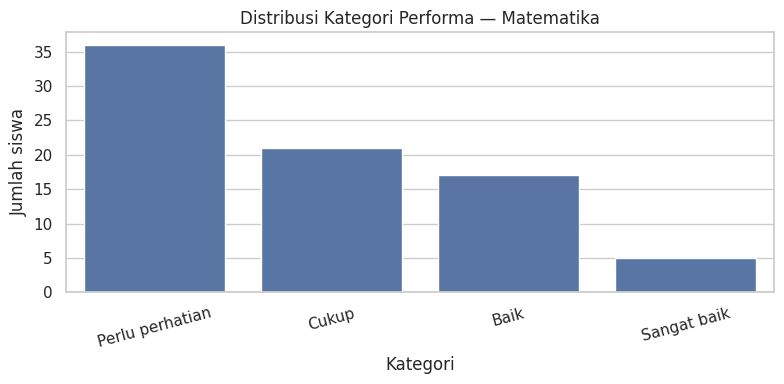

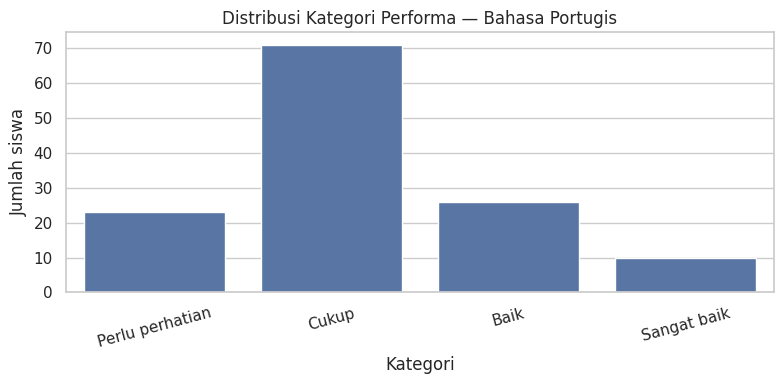

In [19]:
def plot_categories(summary, subject):
    plt.figure(figsize=(8, 4))
    sns.barplot(data=summary, x="Kategori", y="Jumlah siswa")
    plt.title(f"Distribusi Kategori Performa — {subject}")
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

plot_categories(summary_mat, "Matematika")
plot_categories(summary_por, "Bahasa Portugis")

In [20]:
metrics = pd.DataFrame([
    {"Mata Pelajaran": "Matematika", "Model": mat_bundle["model_name"],
     "MAE": mean_absolute_error(y_mat, pred_mat),
     "RMSE": np.sqrt(mean_squared_error(y_mat, pred_mat)),
     "R2": r2_score(y_mat, pred_mat)},
    {"Mata Pelajaran": "Bahasa Portugis", "Model": por_bundle["model_name"],
     "MAE": mean_absolute_error(y_por, pred_por),
     "RMSE": np.sqrt(mean_squared_error(y_por, pred_por)),
     "R2": r2_score(y_por, pred_por)}
])
display(metrics.round(4))

,Mata Pelajaran,Model,MAE,RMSE,R2
0,Matematika,Random Forest,1.2115,2.0415,0.7967
1,Bahasa Portugis,Random Forest,0.7211,1.2089,0.8501


In [21]:
def get_permutation_importance(X, y, bundle, subject):
    X_ready = bundle["preprocessor"].transform(X[bundle["features"]])
    result = permutation_importance(
        bundle["model"], X_ready, y,
        scoring="neg_mean_absolute_error",
        n_repeats=10, random_state=42, n_jobs=-1
    )
    names = bundle["preprocessor"].get_feature_names_out()
    table = pd.DataFrame({
        "Fitur": names,
        "Importance_MAE": result.importances_mean,
        "Std": result.importances_std
    }).sort_values("Importance_MAE", ascending=False)
    print(subject, "— 15 fitur teratas")
    display(table.head(15))
    return table

perm_mat = get_permutation_importance(X_mat, y_mat, mat_bundle, "Matematika")
perm_por = get_permutation_importance(X_por, y_por, por_bundle, "Bahasa Portugis")

Matematika — 15 fitur teratas


,Fitur,Importance_MAE,Std
14,numeric__G2,3.397541,0.209390
12,numeric__absences,0.316460,0.093352
0,numeric__age,0.030657,0.016212
13,numeric__G1,0.021042,0.006665
10,numeric__Walc,0.006663,0.008219
6,numeric__famrel,0.006256,0.007397
3,numeric__traveltime,0.005503,0.004784
8,numeric__goout,0.004561,0.006212
4,numeric__studytime,0.003742,0.003883
2,numeric__Fedu,0.002738,0.003215


Bahasa Portugis — 15 fitur teratas


,Fitur,Importance_MAE,Std
14,numeric__G2,2.484602,0.127276
12,numeric__absences,0.057682,0.024748
0,numeric__age,0.024666,0.007940
1,numeric__Medu,0.016281,0.011913
13,numeric__G1,0.013460,0.011397
37,categorical__reason_other,0.005016,0.004437
10,numeric__Walc,0.004341,0.005651
11,numeric__health,0.004190,0.007161
5,numeric__failures,0.003352,0.002525
44,categorical__famsup_no,0.003225,0.002356


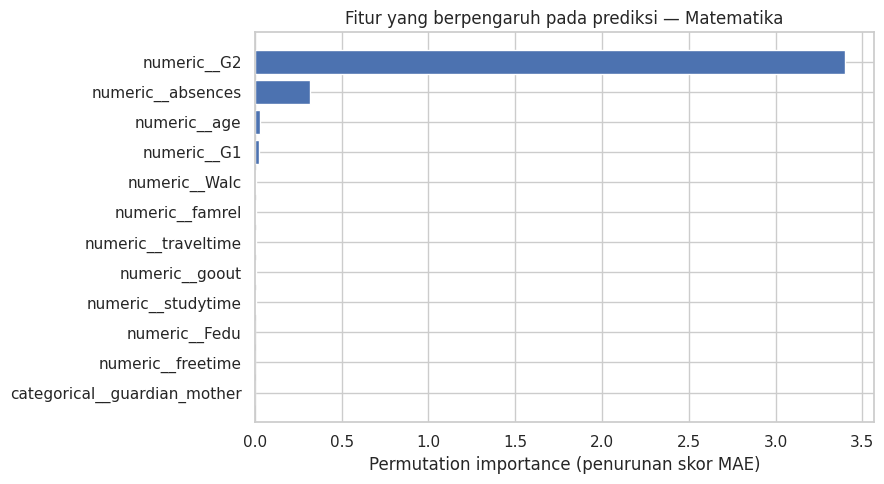

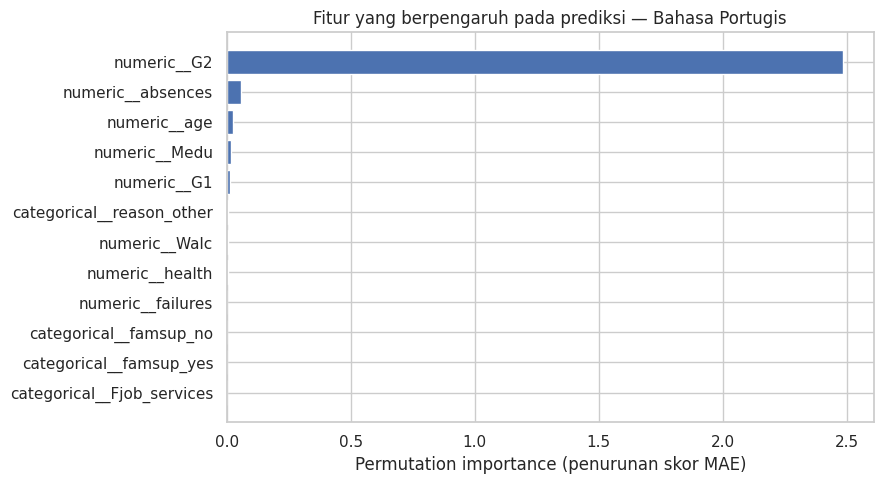

In [22]:
def plot_importance(table, subject, top_n=12):
    top = table.head(top_n).sort_values("Importance_MAE")
    plt.figure(figsize=(9, 5))
    plt.barh(top["Fitur"], top["Importance_MAE"])
    plt.xlabel("Permutation importance (penurunan skor MAE)")
    plt.title(f"Fitur yang berpengaruh pada prediksi — {subject}")
    plt.tight_layout()
    plt.show()

plot_importance(perm_mat, "Matematika")
plot_importance(perm_por, "Bahasa Portugis")

In [23]:
OUTPUT = Path("/content/stage4_outputs")
OUTPUT.mkdir(exist_ok=True)

report_mat.to_csv(OUTPUT / "student_performance_matematika.csv", index=False)
report_por.to_csv(OUTPUT / "student_performance_portugis.csv", index=False)
summary_mat.to_csv(OUTPUT / "category_summary_matematika.csv", index=False)
summary_por.to_csv(OUTPUT / "category_summary_portugis.csv", index=False)
metrics.to_csv(OUTPUT / "stage4_model_metrics.csv", index=False)
perm_mat.to_csv(OUTPUT / "permutation_importance_matematika.csv", index=False)
perm_por.to_csv(OUTPUT / "permutation_importance_portugis.csv", index=False)

print("File tersimpan:")
for p in sorted(OUTPUT.iterdir()):
    print(p.name)

File tersimpan:
category_summary_matematika.csv
category_summary_portugis.csv
permutation_importance_matematika.csv
permutation_importance_portugis.csv
stage4_model_metrics.csv
student_performance_matematika.csv
student_performance_portugis.csv


In [24]:
zip_path = Path("/content/stage4_outputs.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in OUTPUT.iterdir():
        z.write(p, arcname=p.name)

from google.colab import files
files.download(str(zip_path))
print("Selesai. Simpan stage4_outputs.zip.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Selesai. Simpan stage4_outputs.zip.


In [25]:
print("DISTRIBUSI PERFORMA MATEMATIKA")
display(summary_mat)

print("DISTRIBUSI PERFORMA BAHASA PORTUGIS")
display(summary_por)

print("HASIL EVALUASI MODEL")
display(metrics.round(4))

DISTRIBUSI PERFORMA MATEMATIKA


,Kategori,Jumlah siswa
0,Perlu perhatian,36
1,Cukup,21
2,Baik,17
3,Sangat baik,5


DISTRIBUSI PERFORMA BAHASA PORTUGIS


,Kategori,Jumlah siswa
0,Perlu perhatian,23
1,Cukup,71
2,Baik,26
3,Sangat baik,10


HASIL EVALUASI MODEL


,Mata Pelajaran,Model,MAE,RMSE,R2
0,Matematika,Random Forest,1.2115,2.0415,0.7967
1,Bahasa Portugis,Random Forest,0.7211,1.2089,0.8501
